<center><h1>Fan_Jinning_HW5</h1></center>
<br>
<br>

Name: 
<br> Jinning Fan
Github Username: jinningf-cyber
<br>
USC ID: 4608286954

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn

from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

from IPython.display import display

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
repository_url = (
    "https://github.com/jinningf-cyber/DSCI552/"
    "archive/refs/heads/main.zip"
)

with urlopen(repository_url) as response:
    repository_zip = ZipFile(BytesIO(response.read()))

homework_files = []

for path in repository_zip.namelist():
    if "/DSCI552-Homework5/" in path and not path.endswith("/"):
        homework_files.append(path)

if len(homework_files) == 0:
    raise FileNotFoundError("DSCI552-Homework5 was not found in the repository.")


def load_github_file(filename):
    for path in homework_files:
        name = path.rsplit("/", 1)[-1]

        if name.lower() == filename.lower():
            return BytesIO(repository_zip.read(path))

    for path in homework_files:
        if path.lower().endswith(".zip"):
            archive_data = repository_zip.read(path)

            with ZipFile(BytesIO(archive_data)) as archive:
                for member in archive.namelist():
                    name = member.rsplit("/", 1)[-1]

                    if name.lower() == filename.lower():
                        return BytesIO(archive.read(member))

    raise FileNotFoundError(
        f"{filename} was not found in DSCI552-Homework5."
    )


file_names = []

for path in homework_files:
    file_names.append(path.split("/DSCI552-Homework5/", 1)[1])

pd.DataFrame({"Repository File": file_names})

,Repository File
0,.DS_Store
1,Acute_Inflammations/acute+inflammations.zip
2,Acute_Inflammations/diagnosis.data
3,Acute_Inflammations/diagnosis.names
4,Communities_and_Crime/communities+and+crime.zip
5,Communities_and_Crime/communities.data
6,Communities_and_Crime/communities.names


The data contain six predictors and two binary diagnosis labels.

I use the label powerset method to combine the two diagnosis labels into
one multiclass outcome. Each class represents a particular combination
of inflammation and nephritis.

In [4]:
acute_columns = [
    "Temperature",
    "Nausea",
    "LumbarPain",
    "UrinePushing",
    "MicturitionPain",
    "UrethraSymptoms",
    "Inflammation",
    "Nephritis"
]

acute_df = pd.read_csv(
    load_github_file("diagnosis.data"),
    sep="\t",
    header=None,
    names=acute_columns,
    encoding="utf-16",
    decimal=","
)

for col in acute_columns[1:]:
    acute_df[col] = acute_df[col].str.strip().map({
        "no": 0,
        "yes": 1
    })

print("Data shape:", acute_df.shape)

acute_df.head()

Data shape: (120, 8)


,Temperature,Nausea,LumbarPain,UrinePushing,MicturitionPain,UrethraSymptoms,Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [5]:
X_acute = acute_df.iloc[:, :6].copy()

inflammation_labels = acute_df["Inflammation"].map({
    0: "no",
    1: "yes"
})

nephritis_labels = acute_df["Nephritis"].map({
    0: "no",
    1: "yes"
})

y_acute = (
    "Inflammation=" + inflammation_labels
    + ", Nephritis=" + nephritis_labels
)

label_counts_df = y_acute.value_counts().to_frame("Count")
label_counts_df.index.name = "Diagnosis Combination"

label_counts_df

,Count
Diagnosis Combination,
"Inflammation=yes, Nephritis=no",40
"Inflammation=no, Nephritis=yes",31
"Inflammation=no, Nephritis=no",30
"Inflammation=yes, Nephritis=yes",19


### (b) Build a decision tree

Training accuracy: 1.0
Tree depth: 4
Number of leaves: 6


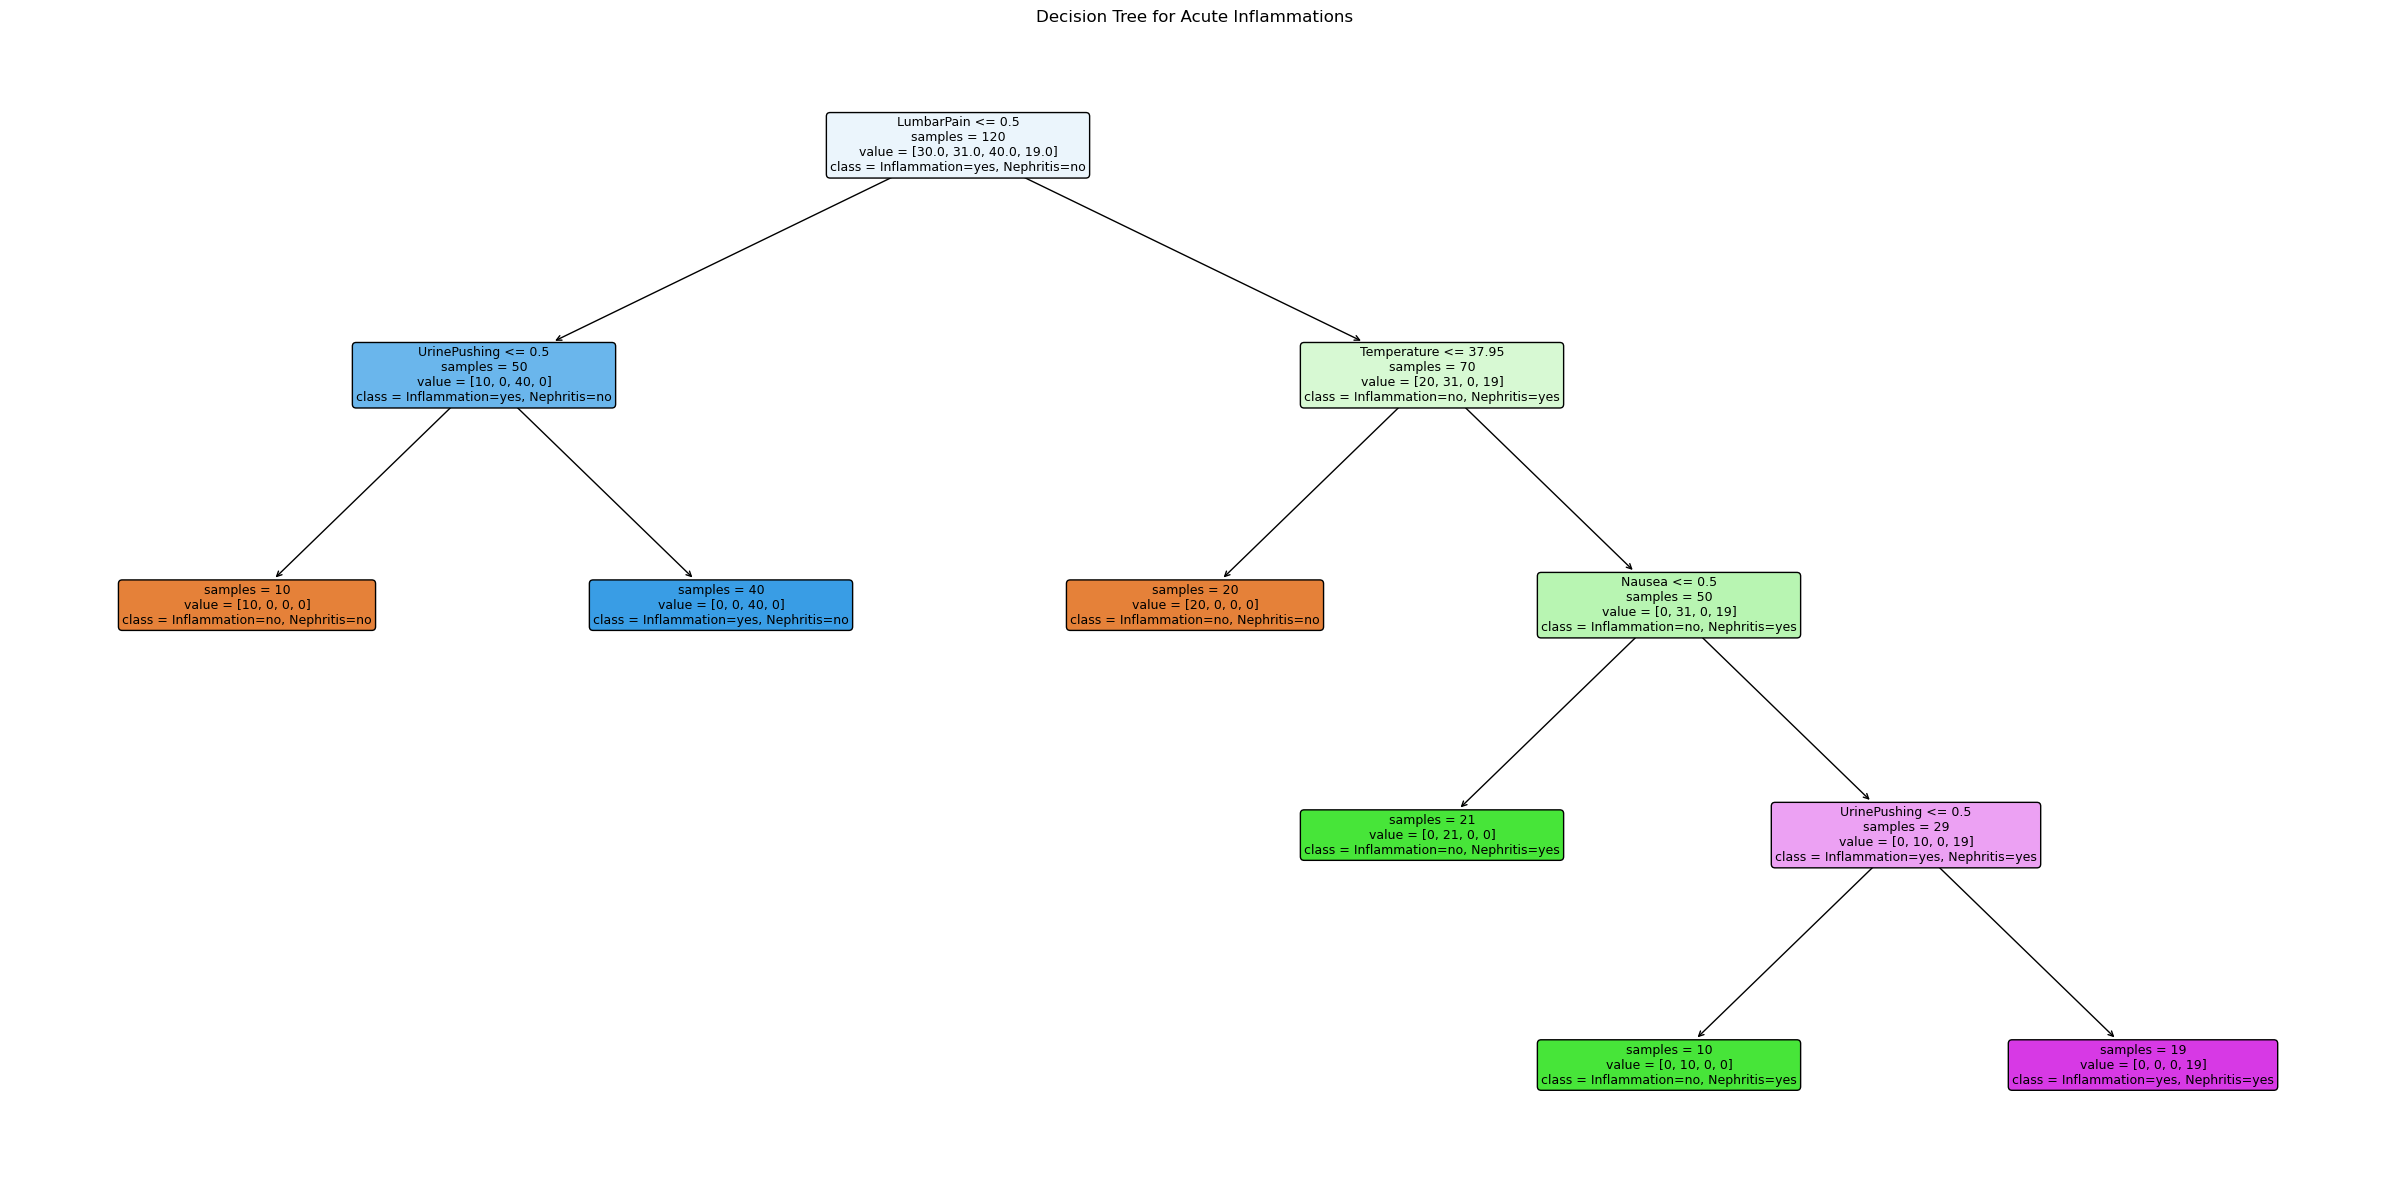

In [6]:
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_acute, y_acute)

print("Training accuracy:", round(full_tree.score(X_acute, y_acute), 4))
print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())

plt.figure(figsize=(24, 12))

plot_tree(
    full_tree,
    feature_names=X_acute.columns.tolist(),
    class_names=full_tree.classes_.tolist(),
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=9
)

plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

I fit an unrestricted decision tree to the entire data set, as required.
The training accuracy describes the fit to these observations rather
than performance on new patients.

### (c) Convert the decision rules

In [9]:
def extract_rules(model, feature_names):
    tree = model.tree_
    rules = []

    def visit_node(node, conditions):
        left_node = tree.children_left[node]
        right_node = tree.children_right[node]

        if left_node != right_node:
            feature = feature_names[tree.feature[node]]
            threshold = tree.threshold[node]

            if feature == "Temperature":
                left_condition = f"{feature} <= {threshold:.2f}"
                right_condition = f"{feature} > {threshold:.2f}"
            else:
                left_condition = f"{feature} = no"
                right_condition = f"{feature} = yes"

            visit_node(
                left_node,
                conditions + [left_condition]
            )

            visit_node(
                right_node,
                conditions + [right_condition]
            )

        else:
            values = tree.value[node].ravel()
            class_index = np.argmax(values)
            prediction = model.classes_[class_index]

            if len(conditions) == 0:
                condition_text = "TRUE"
            else:
                condition_text = " AND ".join(conditions)

            rule = (
                f"IF {condition_text} "
                f"THEN {prediction} "
                f"(samples = {tree.n_node_samples[node]})"
            )

            rules.append(rule)

    visit_node(0, [])

    return rules


full_rules = extract_rules(
    full_tree,
    X_acute.columns.tolist()
)

for i, rule in enumerate(full_rules, start=1):
    print(f"Rule {i}: {rule}\n")

Rule 1: IF LumbarPain = no AND UrinePushing = no THEN Inflammation=no, Nephritis=no (samples = 10)

Rule 2: IF LumbarPain = no AND UrinePushing = yes THEN Inflammation=yes, Nephritis=no (samples = 40)

Rule 3: IF LumbarPain = yes AND Temperature <= 37.95 THEN Inflammation=no, Nephritis=no (samples = 20)

Rule 4: IF LumbarPain = yes AND Temperature > 37.95 AND Nausea = no THEN Inflammation=no, Nephritis=yes (samples = 21)

Rule 5: IF LumbarPain = yes AND Temperature > 37.95 AND Nausea = yes AND UrinePushing = no THEN Inflammation=no, Nephritis=yes (samples = 10)

Rule 6: IF LumbarPain = yes AND Temperature > 37.95 AND Nausea = yes AND UrinePushing = yes THEN Inflammation=yes, Nephritis=yes (samples = 19)



Each path from the root to a leaf gives one IF-THEN rule.
For binary symptoms, 0 represents no and 1 represents yes.

### (d) Cost-Complexity Pruning

Cost-complexity pruning minimizes

$$
R_\alpha(T) = R(T) + \alpha |T|,
$$

where $R(T)$ is the total weighted leaf impurity and $|T|$
is the number of leaves.

I evaluate the pruning candidates with stratified five-fold
cross-validation. I then select the smallest candidate tree whose
mean accuracy is within one standard error of the best mean accuracy.
This gives a clear criterion for balancing accuracy and interpretability.

In [10]:
pruning_path = full_tree.cost_complexity_pruning_path(
    X_acute,
    y_acute
)

ccp_alphas = np.unique(pruning_path.ccp_alphas)

tree_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pruning_results = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        ccp_alpha=alpha,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_acute,
        y_acute,
        cv=tree_cv,
        scoring="accuracy"
    )

    model.fit(X_acute, y_acute)

    pruning_results.append({
        "Alpha": alpha,
        "CV Accuracy": scores.mean(),
        "CV SE": scores.std(ddof=1) / np.sqrt(len(scores)),
        "Training Accuracy": model.score(X_acute, y_acute),
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves()
    })

pruning_df = pd.DataFrame(pruning_results)

pruning_df.round(6)

,Alpha,CV Accuracy,CV SE,Training Accuracy,Depth,Leaves
0,0.000000,0.991667,0.008333,1.000000,4,6
1,0.098167,0.858333,0.025000,0.841667,2,4
2,0.133333,0.758333,0.033333,0.758333,2,3
3,0.182000,0.666667,0.029463,0.591667,1,2
4,0.222917,0.483333,0.061237,0.333333,0,1


In [11]:
best_index = pruning_df["CV Accuracy"].idxmax()
best_result = pruning_df.loc[best_index]

accuracy_cutoff = (
    best_result["CV Accuracy"]
    - best_result["CV SE"]
)

acceptable_trees_df = pruning_df[
    pruning_df["CV Accuracy"] >= accuracy_cutoff
].copy()

acceptable_trees_df = acceptable_trees_df.sort_values(
    ["Leaves", "Alpha"],
    ascending=[True, False]
)

selected_result = acceptable_trees_df.iloc[0]
selected_alpha = selected_result["Alpha"]

pruned_tree = DecisionTreeClassifier(
    ccp_alpha=selected_alpha,
    random_state=42
)

pruned_tree.fit(X_acute, y_acute)

print("Selected alpha:", selected_alpha)
print("Accuracy cutoff:", round(accuracy_cutoff, 4))

tree_comparison_df = pd.DataFrame({
    "Model": ["Full Tree", "Pruned Tree"],
    "Depth": [
        full_tree.get_depth(),
        pruned_tree.get_depth()
    ],
    "Leaves": [
        full_tree.get_n_leaves(),
        pruned_tree.get_n_leaves()
    ],
    "Training Accuracy": [
        full_tree.score(X_acute, y_acute),
        pruned_tree.score(X_acute, y_acute)
    ]
})

tree_comparison_df.round(4)

Selected alpha: 0.0
Accuracy cutoff: 0.9833


,Model,Depth,Leaves,Training Accuracy
0,Full Tree,4,6,1.0
1,Pruned Tree,4,6,1.0


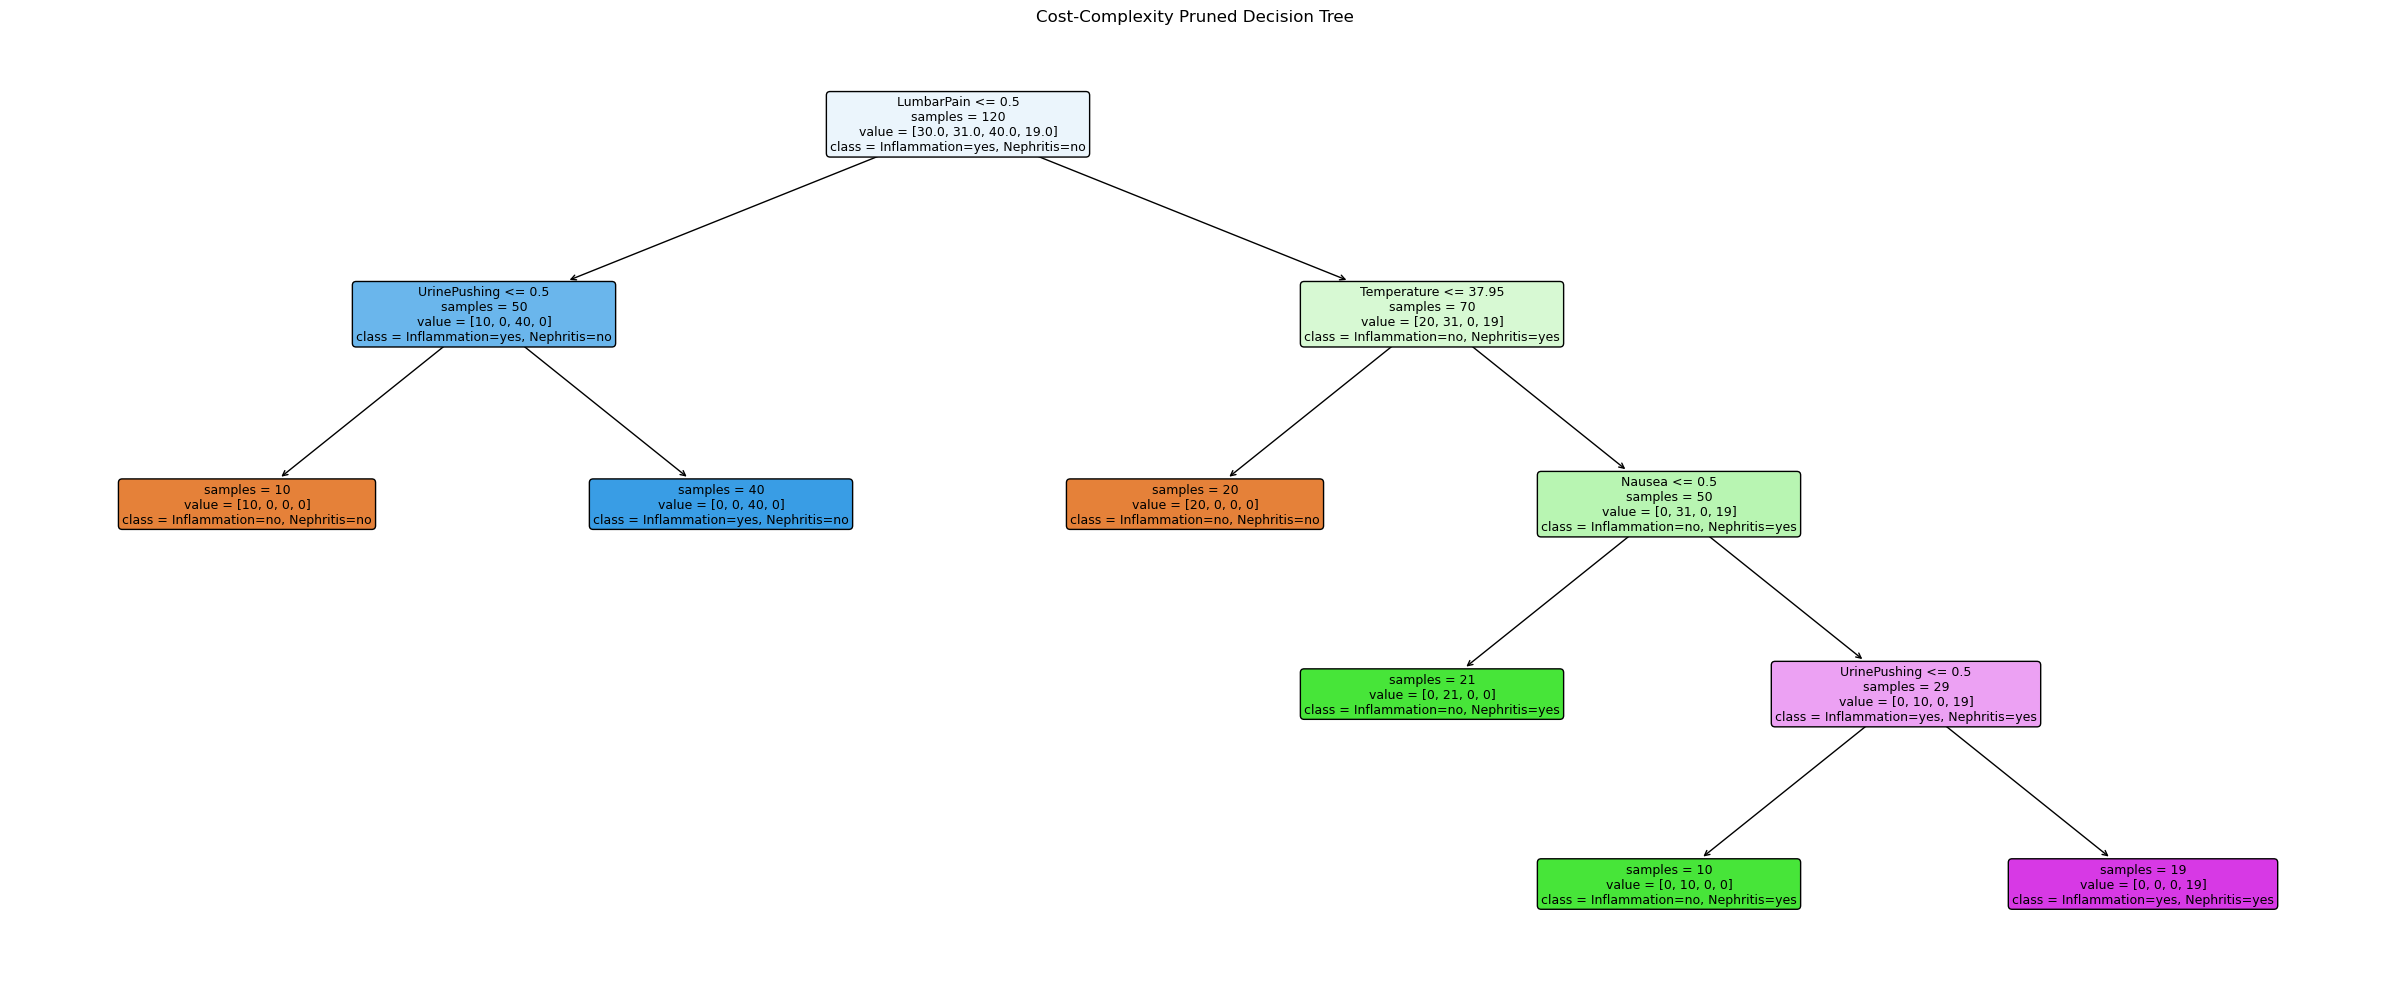

Rule 1: IF LumbarPain = no AND UrinePushing = no THEN Inflammation=no, Nephritis=no (samples = 10)

Rule 2: IF LumbarPain = no AND UrinePushing = yes THEN Inflammation=yes, Nephritis=no (samples = 40)

Rule 3: IF LumbarPain = yes AND Temperature <= 37.95 THEN Inflammation=no, Nephritis=no (samples = 20)

Rule 4: IF LumbarPain = yes AND Temperature > 37.95 AND Nausea = no THEN Inflammation=no, Nephritis=yes (samples = 21)

Rule 5: IF LumbarPain = yes AND Temperature > 37.95 AND Nausea = yes AND UrinePushing = no THEN Inflammation=no, Nephritis=yes (samples = 10)

Rule 6: IF LumbarPain = yes AND Temperature > 37.95 AND Nausea = yes AND UrinePushing = yes THEN Inflammation=yes, Nephritis=yes (samples = 19)

No smaller candidate subtree satisfied the one-standard-error criterion.


In [12]:
plt.figure(figsize=(24, 10))

plot_tree(
    pruned_tree,
    feature_names=X_acute.columns.tolist(),
    class_names=pruned_tree.classes_.tolist(),
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=9
)

plt.title("Cost-Complexity Pruned Decision Tree")
plt.tight_layout()
plt.show()

pruned_rules = extract_rules(
    pruned_tree,
    X_acute.columns.tolist()
)

for i, rule in enumerate(pruned_rules, start=1):
    print(f"Rule {i}: {rule}\n")

if pruned_tree.get_n_leaves() < full_tree.get_n_leaves():
    print(
        "The selected tree uses fewer rules while satisfying "
        "the one-standard-error criterion."
    )
else:
    print(
        "No smaller candidate subtree satisfied "
        "the one-standard-error criterion."
    )

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [13]:
names_text = load_github_file(
    "communities.names"
).read().decode("utf-8-sig")

column_names = []

for line in names_text.splitlines():
    line = line.strip()

    if line.lower().startswith("@attribute"):
        column_name = line.split()[1].strip("'\"")
        column_names.append(column_name)

communities_df = pd.read_csv(
    load_github_file("communities.data"),
    header=None,
    na_values="?"
)

communities_df.columns = column_names

train = communities_df.iloc[:1495].copy()
test = communities_df.iloc[1495:].copy()

data_shape_df = pd.DataFrame({
    "Data Set": ["Full Data", "Training", "Test"],
    "Rows": [
        len(communities_df),
        len(train),
        len(test)
    ],
    "Columns": [
        communities_df.shape[1],
        train.shape[1],
        test.shape[1]
    ]
})

display(data_shape_df)

communities_df.head()

,Data Set,Rows,Columns
0,Full Data,1994,128
1,Training,1495,128
2,Test,499,128


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


The response variable is ViolentCrimesPerPop.

I use the first 1495 observations as the training set and the remaining
observations as the test set, keeping the original row order.

### (b) Missing values

In [14]:
nonpredictive_features = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

target = "ViolentCrimesPerPop"

drop_columns = nonpredictive_features + [target]

X_train = train.drop(columns=drop_columns).astype(float)
X_test = test.drop(columns=drop_columns).astype(float)

y_train = train[target].astype(float)
y_test = test[target].astype(float)

missing_values_df = pd.DataFrame({
    "Training Missing": X_train.isnull().sum(),
    "Test Missing": X_test.isnull().sum()
})

missing_values_df = missing_values_df[
    (missing_values_df["Training Missing"] > 0)
    | (missing_values_df["Test Missing"] > 0)
]

print("Number of predictors:", X_train.shape[1])

missing_values_df

Number of predictors: 122


,Training Missing,Test Missing
OtherPerCap,1,0
LemasSwornFT,1256,419
LemasSwFTPerPop,1256,419
LemasSwFTFieldOps,1256,419
LemasSwFTFieldPerPop,1256,419
LemasTotalReq,1256,419
LemasTotReqPerPop,1256,419
PolicReqPerOffic,1256,419
PolicPerPop,1256,419
RacialMatchCommPol,1256,419


In [15]:
mean_imputer = SimpleImputer(strategy="mean")

X_train_imputed = pd.DataFrame(
    mean_imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    mean_imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

imputation_check_df = pd.DataFrame({
    "Data Set": ["Training", "Test"],
    "Missing After Imputation": [
        X_train_imputed.isnull().sum().sum(),
        X_test_imputed.isnull().sum().sum()
    ]
})

imputation_check_df

,Data Set,Missing After Imputation
0,Training,0
1,Test,0


I remove state, county, community, communityname, and fold because
they are nonpredictive identifiers.

Missing predictor values are replaced with training-set column means.
For cross-validation, imputation is included in each model pipeline
so that the means are estimated only from the corresponding training fold.

The separately imputed tables below are used for exploratory analysis.
All regression models use the full set of remaining predictors.

### (c) Plot a correlation matrix

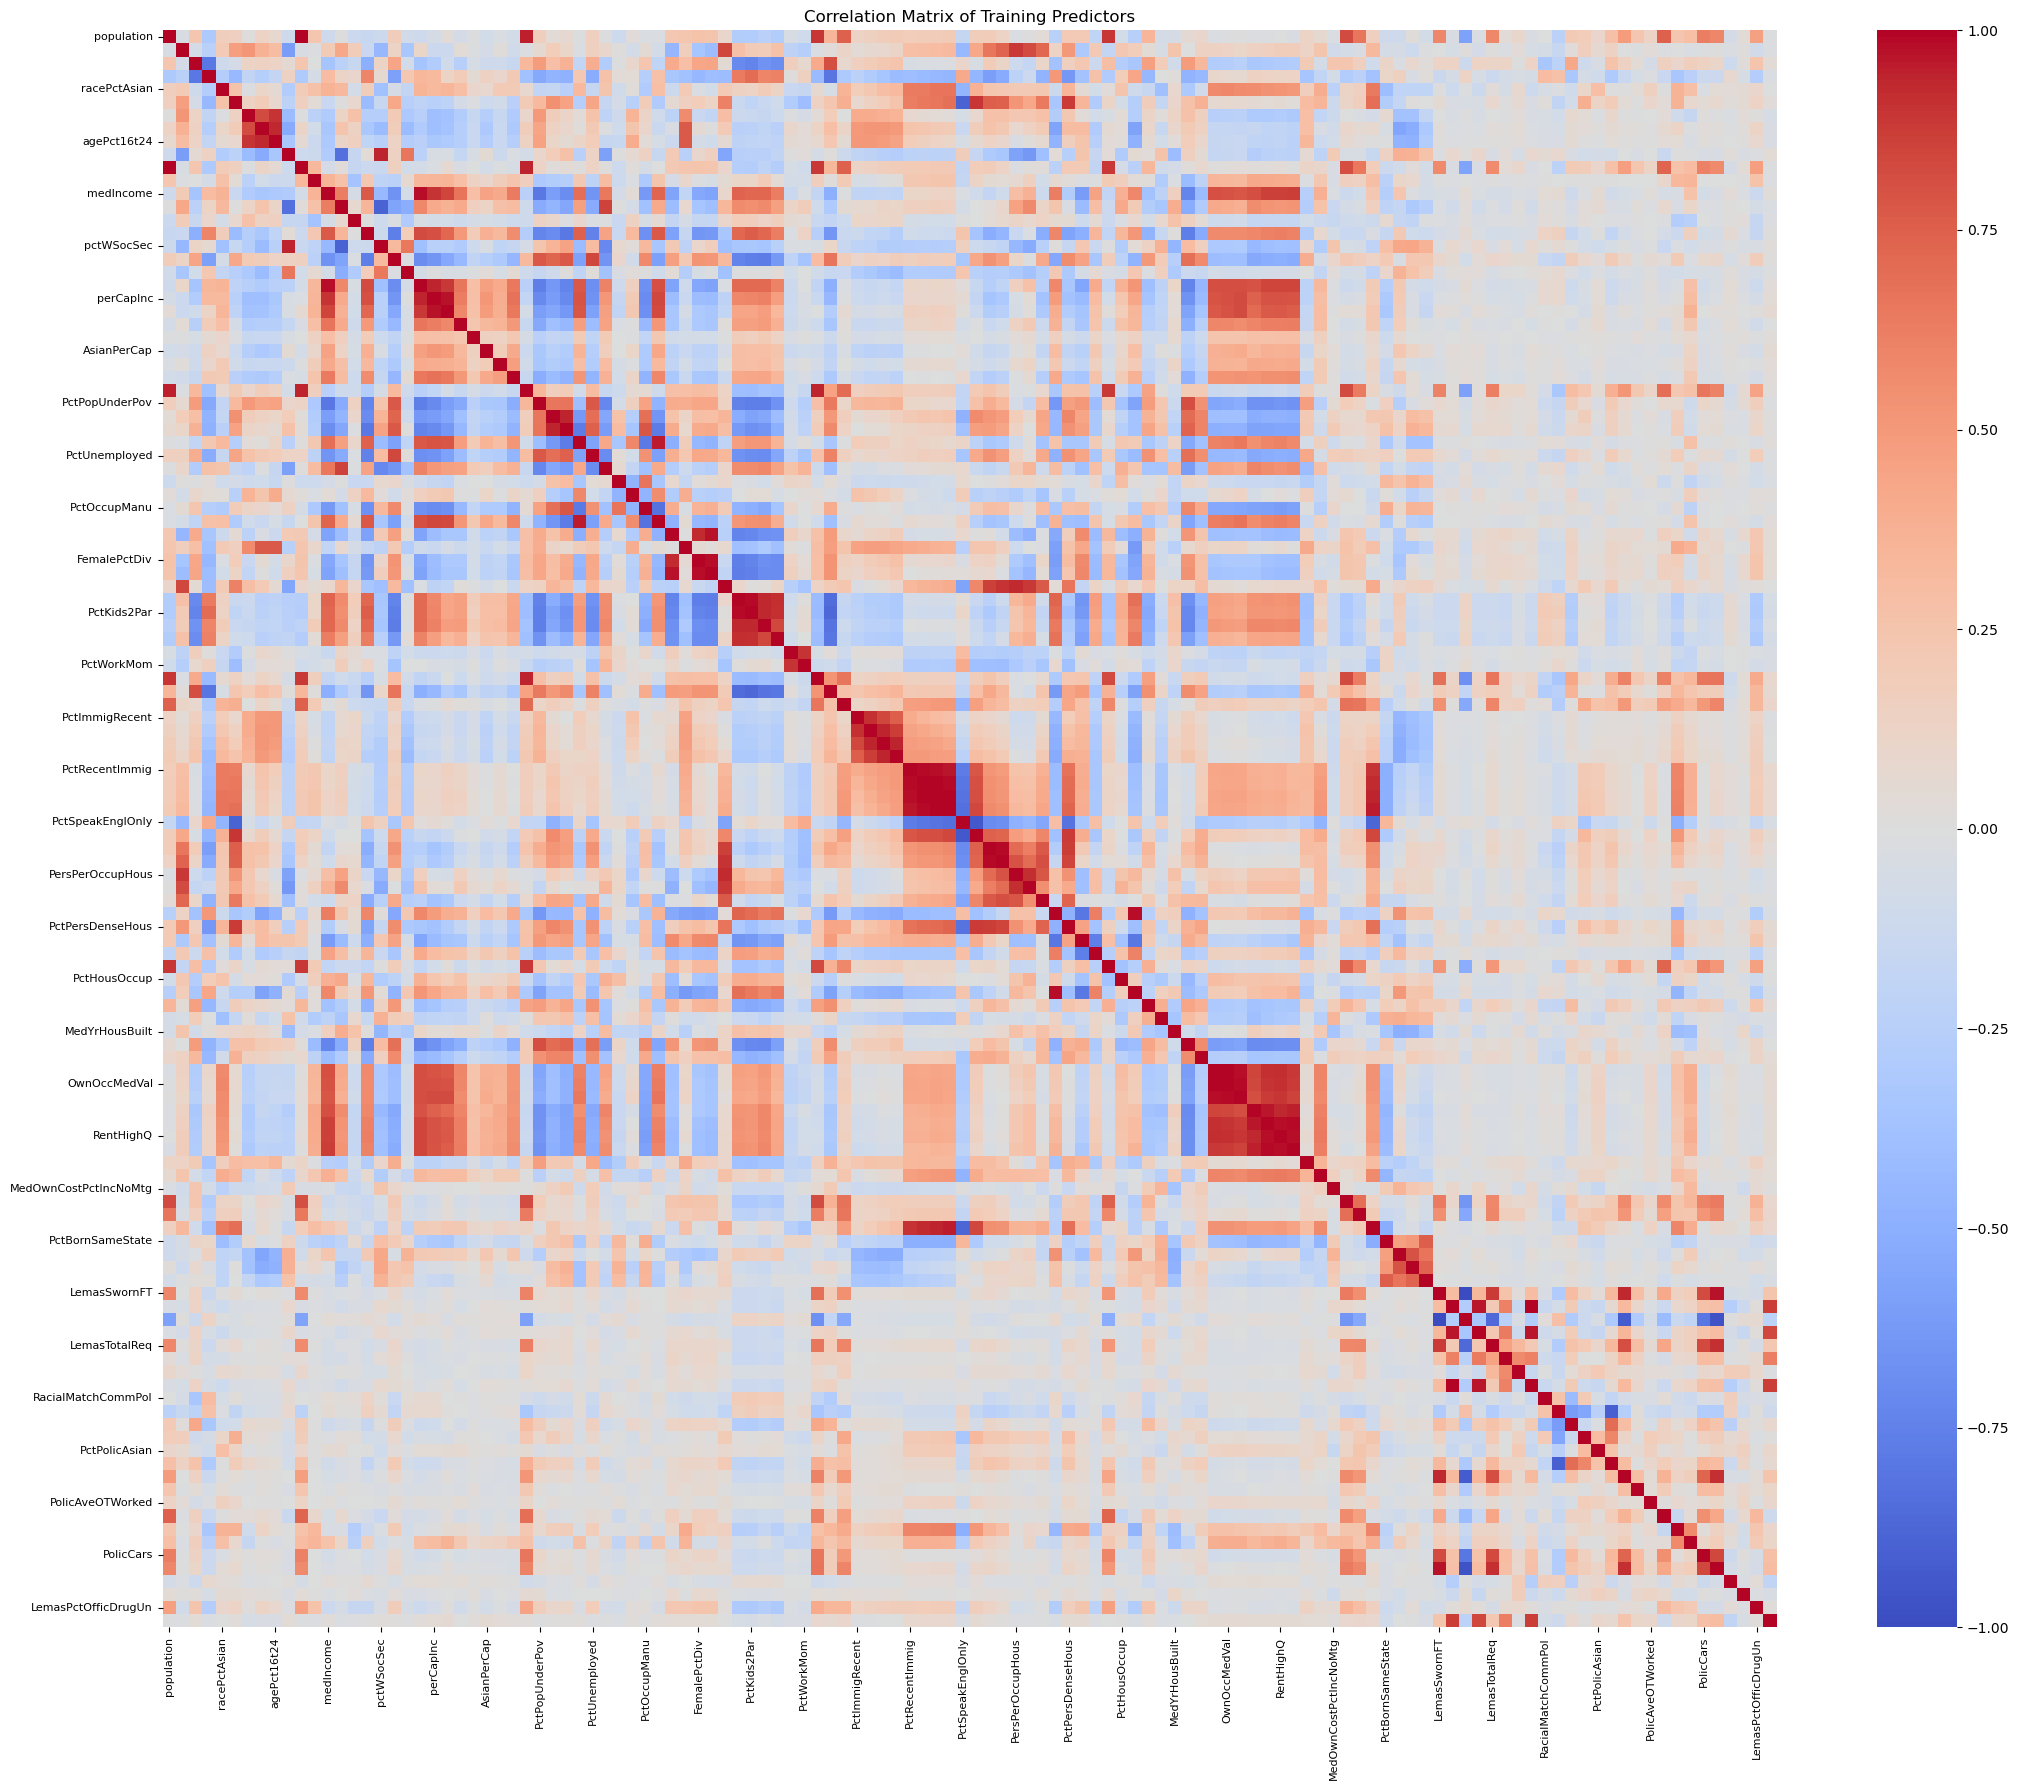

In [16]:
correlation_df = X_train_imputed.corr()

plt.figure(figsize=(22, 18))

seaborn.heatmap(
    correlation_df,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=4,
    yticklabels=4
)

plt.title("Correlation Matrix of Training Predictors")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

I calculate the predictor correlation matrix using the imputed training
data. Large absolute correlations indicate that some predictors contain
similar information, which can make least-squares coefficients unstable.

### (d) Calculate the Coefficient of Variation CV

For each predictor, I calculate

$$
CV = \frac{s}{m},
$$

where $s$ is the sample standard deviation and $m$ is the sample mean.

I use the imputed training data and set $ddof=1$ when calculating
the sample standard deviation. CV is undefined when the mean is zero.

In [17]:
feature_mean = X_train_imputed.mean()
feature_std = X_train_imputed.std(ddof=1)

feature_cv = feature_std / feature_mean.replace(0, np.nan)

CV_df = pd.DataFrame({
    "Mean": feature_mean,
    "Sample Standard Deviation": feature_std,
    "CV": feature_cv
})

CV_df = CV_df.sort_values(
    "CV",
    ascending=False
)

CV_df.round(4)

,Mean,Sample Standard Deviation,CV
NumStreet,0.0230,0.0987,4.2929
NumInShelters,0.0296,0.1027,3.4710
NumIlleg,0.0372,0.1138,3.0590
NumImmig,0.0306,0.0895,2.9266
LemasPctOfficDrugUn,0.0933,0.2382,2.5529
...,...,...,...
NumKindsDrugsSeiz,0.5521,0.0797,0.1444
RacialMatchCommPol,0.6823,0.0920,0.1349
PctPolicWhite,0.7253,0.0891,0.1228
LemasPctPolicOnPatr,0.7131,0.0825,0.1157


### (e) Scatter plots and box plots for highest CV features

The required number of features is

$$
\left\lfloor \sqrt{128} \right\rfloor = 11.
$$

I select the 11 predictors with the highest CV and plot each against
ViolentCrimesPerPop. I also use box plots to examine their distributions.

In [18]:
number_of_features = int(np.floor(np.sqrt(128)))

top_CV_df = CV_df.dropna(subset=["CV"]).head(
    number_of_features
)

selected_features = top_CV_df.index.tolist()

print("Number of selected features:", len(selected_features))

top_CV_df.round(4)

Number of selected features: 11


,Mean,Sample Standard Deviation,CV
NumStreet,0.0230,0.0987,4.2929
NumInShelters,0.0296,0.1027,3.4710
NumIlleg,0.0372,0.1138,3.0590
NumImmig,0.0306,0.0895,2.9266
LemasPctOfficDrugUn,0.0933,0.2382,2.5529
NumUnderPov,0.0568,0.1332,2.3424
population,0.0582,0.1304,2.2411
numbUrban,0.0646,0.1318,2.0385
HousVacant,0.0765,0.1505,1.9685
LandArea,0.0641,0.1055,1.6454


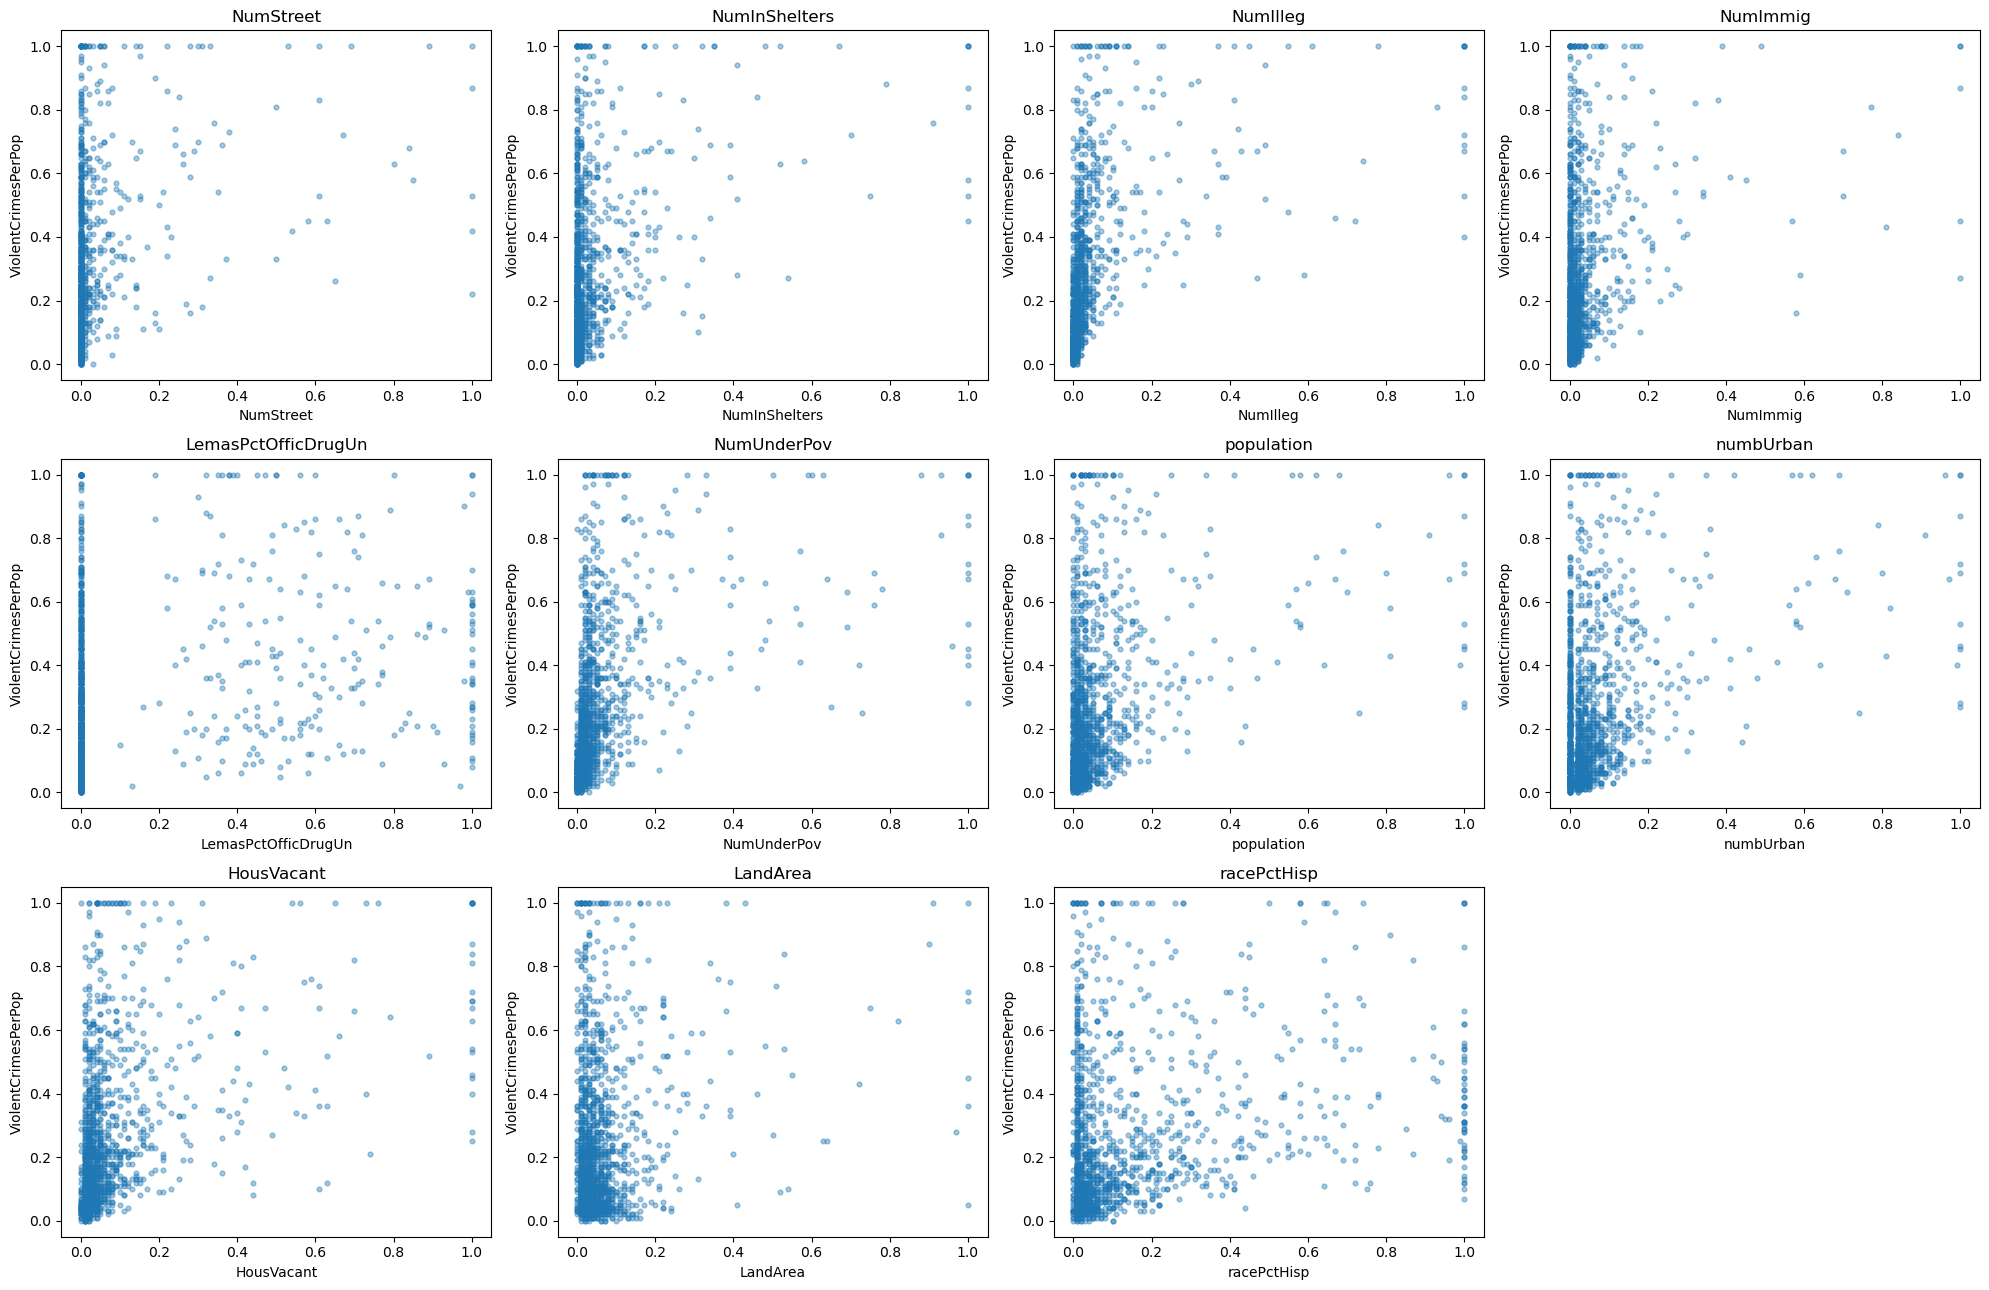

In [19]:
fig, axes = plt.subplots(
    3,
    4,
    figsize=(20, 13)
)

axes = axes.ravel()

for i, col in enumerate(selected_features):
    axes[i].scatter(
        X_train_imputed[col],
        y_train,
        s=12,
        alpha=0.4
    )

    axes[i].set_xlabel(col)
    axes[i].set_ylabel("ViolentCrimesPerPop")
    axes[i].set_title(col)

for i in range(len(selected_features), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

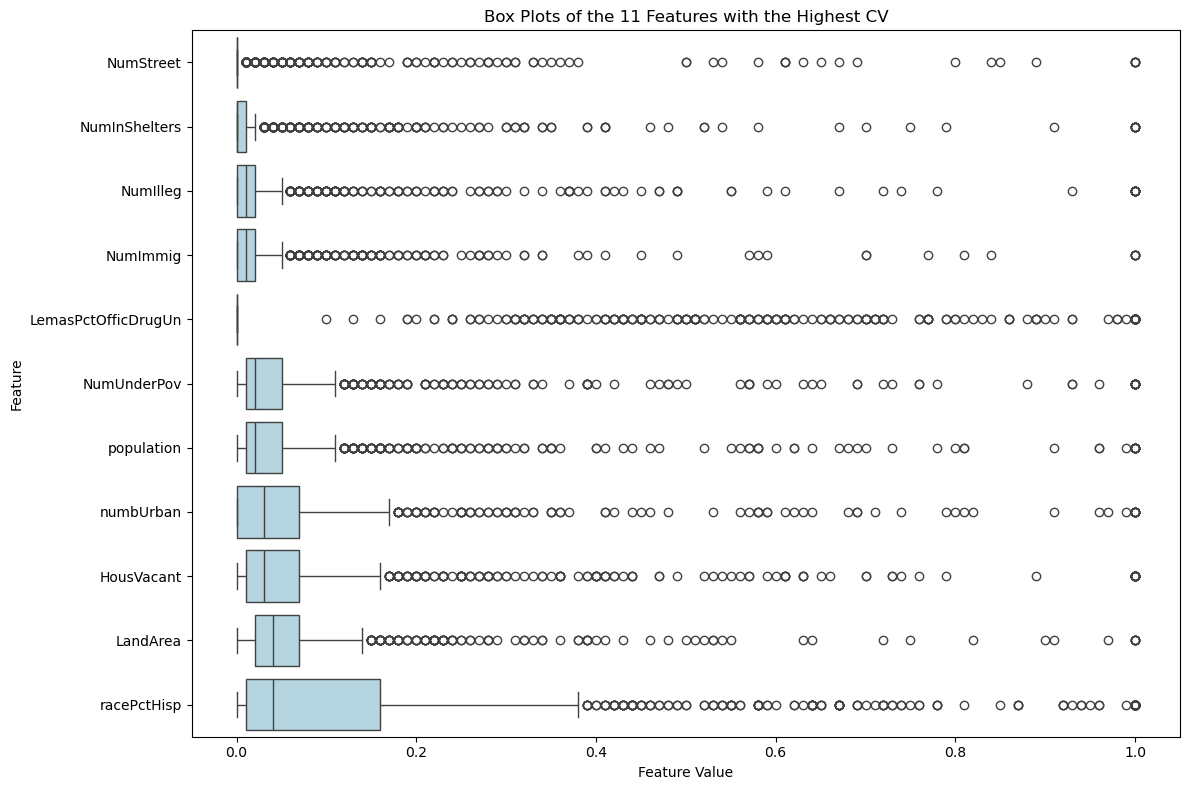

In [20]:
plt.figure(figsize=(12, 8))

seaborn.boxplot(
    data=X_train_imputed[selected_features],
    orient="h",
    color="lightblue"
)

plt.xlabel("Feature Value")
plt.ylabel("Feature")
plt.title("Box Plots of the 11 Features with the Highest CV")
plt.tight_layout()
plt.show()

The scatter plots alone cannot establish statistical significance.
They can suggest associations, nonlinear patterns, and unusual observations,
but they do not account for other predictors or sampling uncertainty.

A high CV measures variation relative to the mean. It does not imply
a strong relationship with the response. Statistical significance requires
an appropriate inferential analysis and its assumptions.

The 11 selected features are used only for this exploratory section.
The regression models below use all remaining predictors.

### (f) Fit a linear model

In [21]:
regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

regression_results = []

ols_model = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("model", LinearRegression())
])

ols_cv_scores = cross_val_score(
    ols_model,
    X_train,
    y_train,
    cv=regression_cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

ols_cv_mse = -ols_cv_scores.mean()

ols_model.fit(X_train, y_train)

ols_prediction = ols_model.predict(X_test)
ols_test_mse = mean_squared_error(y_test, ols_prediction)

regression_results.append({
    "Model": "Least Squares",
    "Best Parameter": "None",
    "CV MSE": ols_cv_mse,
    "Test MSE": ols_test_mse
})

pd.DataFrame(regression_results).round(6)

,Model,Best Parameter,CV MSE,Test MSE
0,Least Squares,None,0.020795,1.809992e+16


### (g) Fit a ridge regression model

In [22]:
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

ridge_parameters = {
    "model__alpha": np.logspace(-4, 4, 65)
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_parameters,
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

ridge_alpha = ridge_search.best_params_["model__alpha"]
ridge_cv_mse = -ridge_search.best_score_

ridge_prediction = ridge_search.predict(X_test)
ridge_test_mse = mean_squared_error(
    y_test,
    ridge_prediction
)

regression_results.append({
    "Model": "Ridge",
    "Best Parameter": f"lambda = {ridge_alpha:.6g}",
    "CV MSE": ridge_cv_mse,
    "Test MSE": ridge_test_mse
})

ridge_result_df = pd.DataFrame({
    "Selected Lambda": [ridge_alpha],
    "CV MSE": [ridge_cv_mse],
    "Test MSE": [ridge_test_mse]
})

ridge_result_df.round(6)

,Selected Lambda,CV MSE,Test MSE
0,133.352143,0.019753,0.017467


I choose the ridge regularization parameter using five-fold
cross-validation with mean squared error.

Predictors are standardized within each training fold so that the
penalty is applied on a comparable scale. The selected pipeline is
then refitted on the complete training set.

### (h) Fit a LASSO model

In [ ]:


lasso_parameters = {
    "model__alpha": np.logspace(-5, 0, 51)
}

lasso_raw_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("model", Lasso(max_iter=100000, tol=1e-5))
])

lasso_raw_search = GridSearchCV(
    estimator=lasso_raw_pipeline,
    param_grid=lasso_parameters,
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1
)

lasso_raw_search.fit(X_train, y_train)

lasso_raw_alpha = lasso_raw_search.best_params_["model__alpha"]
lasso_raw_cv_mse = -lasso_raw_search.best_score_

lasso_raw_prediction = lasso_raw_search.predict(X_test)

lasso_raw_test_mse = mean_squared_error(
    y_test,
    lasso_raw_prediction
)

lasso_raw_coefficients = pd.Series(
    lasso_raw_search.best_estimator_.named_steps["model"].coef_,
    index=X_train.columns,
    name="Coefficient"
)

lasso_raw_selected_df = lasso_raw_coefficients[
    lasso_raw_coefficients != 0
].to_frame()

regression_results.append({
    "Model": "LASSO Original",
    "Best Parameter": f"lambda = {lasso_raw_alpha:.6g}",
    "CV MSE": lasso_raw_cv_mse,
    "Test MSE": lasso_raw_test_mse
})

display(pd.DataFrame({
    "Selected Lambda": [lasso_raw_alpha],
    "CV MSE": [lasso_raw_cv_mse],
    "Test MSE": [lasso_raw_test_mse],
    "Selected Features": [len(lasso_raw_selected_df)]
}).round(6))

lasso_raw_selected_df.round(6)

,Selected Lambda,CV MSE,Test MSE,Selected Features
0,0.000126,0.019519,0.017733,75


,Coefficient
racepctblack,0.271028
racePctAsian,-0.014162
agePct12t21,0.058857
agePct12t29,-0.247739
pctUrban,0.040270
...,...
PctUsePubTrans,-0.041874
LemasPctPolicOnPatr,0.021573
LemasGangUnitDeploy,0.039757
LemasPctOfficDrugUn,0.003158


In [ ]:
#Standardized LASSO
lasso_scaled_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=100000, tol=1e-5))
])

lasso_scaled_search = GridSearchCV(
    estimator=lasso_scaled_pipeline,
    param_grid=lasso_parameters,
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1
)

lasso_scaled_search.fit(X_train, y_train)

lasso_scaled_alpha = lasso_scaled_search.best_params_["model__alpha"]
lasso_scaled_cv_mse = -lasso_scaled_search.best_score_

lasso_scaled_prediction = lasso_scaled_search.predict(X_test)

lasso_scaled_test_mse = mean_squared_error(
    y_test,
    lasso_scaled_prediction
)

lasso_scaled_coefficients = pd.Series(
    lasso_scaled_search.best_estimator_.named_steps["model"].coef_,
    index=X_train.columns,
    name="Standardized Coefficient"
)

lasso_scaled_selected_df = lasso_scaled_coefficients[
    lasso_scaled_coefficients != 0
].to_frame()

regression_results.append({
    "Model": "LASSO Standardized",
    "Best Parameter": f"lambda = {lasso_scaled_alpha:.6g}",
    "CV MSE": lasso_scaled_cv_mse,
    "Test MSE": lasso_scaled_test_mse
})

display(pd.DataFrame({
    "Selected Lambda": [lasso_scaled_alpha],
    "CV MSE": [lasso_scaled_cv_mse],
    "Test MSE": [lasso_scaled_test_mse],
    "Selected Features": [len(lasso_scaled_selected_df)]
}).round(6))

lasso_scaled_selected_df.round(6)

,Selected Lambda,CV MSE,Test MSE,Selected Features
0,0.000631,0.019634,0.01785,76


,Standardized Coefficient
population,-0.000281
racepctblack,0.069034
racePctAsian,-0.001946
agePct12t21,0.012740
agePct12t29,-0.043360
...,...
PopDens,0.003567
PctUsePubTrans,-0.009880
PolicCars,0.005024
LemasPctPolicOnPatr,0.002114


In [25]:
#Comparison of LASSO Models
lasso_comparison_df = pd.DataFrame({
    "Features": ["Original", "Standardized"],
    "Selected Lambda": [
        lasso_raw_alpha,
        lasso_scaled_alpha
    ],
    "Selected Features": [
        len(lasso_raw_selected_df),
        len(lasso_scaled_selected_df)
    ],
    "CV MSE": [
        lasso_raw_cv_mse,
        lasso_scaled_cv_mse
    ],
    "Test MSE": [
        lasso_raw_test_mse,
        lasso_scaled_test_mse
    ]
})

display(lasso_comparison_df.round(6))

mse_difference = lasso_scaled_test_mse - lasso_raw_test_mse

if mse_difference < 0:
    print(
        "Standardized LASSO has a lower test MSE by "
        f"{abs(mse_difference):.6f}."
    )
elif mse_difference > 0:
    print(
        "Original-scale LASSO has a lower test MSE by "
        f"{mse_difference:.6f}."
    )
else:
    print("The two LASSO models have the same test MSE.")

,Features,Selected Lambda,Selected Features,CV MSE,Test MSE
0,Original,0.000126,75,0.019519,0.017733
1,Standardized,0.000631,76,0.019634,0.017850


Original-scale LASSO has a lower test MSE by 0.000117.


I first fit LASSO using the original feature scales, with mean imputation.
I then repeat the analysis with standardized predictors.

In each case, the regularization parameter is selected by five-fold
cross-validation. Features with nonzero fitted coefficients are selected
by the model.

I show that standardization changes the relative penalty applied to the predictors.
Although the original features are normalized, their standard deviations
can still differ.

Without standardization, predictors with smaller variation may require
larger coefficients and therefore receive a larger effective penalty.
Standardization can change both the selected variables and the test error.

The standardized coefficients describe a one-standard-deviation change
in each predictor, so their magnitudes are on a different scale from
the original-scale coefficients.

### (i) Fit a PCR model

In [26]:
pcr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("model", LinearRegression())
])

component_values = list(
    range(1, X_train.shape[1] + 1)
)

pcr_parameters = {
    "pca__n_components": component_values
}

pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid=pcr_parameters,
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1
)

pcr_search.fit(X_train, y_train)

best_M = pcr_search.best_params_["pca__n_components"]
pcr_cv_mse = -pcr_search.best_score_

pcr_prediction = pcr_search.predict(X_test)
pcr_test_mse = mean_squared_error(
    y_test,
    pcr_prediction
)

regression_results.append({
    "Model": "PCR",
    "Best Parameter": f"M = {best_M}",
    "CV MSE": pcr_cv_mse,
    "Test MSE": pcr_test_mse
})

pcr_result_df = pd.DataFrame({
    "Selected M": [best_M],
    "CV MSE": [pcr_cv_mse],
    "Test MSE": [pcr_test_mse]
})

pcr_result_df.round(6)

,Selected M,CV MSE,Test MSE
0,60,0.020217,0.0184


For PCR, I apply mean imputation, standardization, PCA, and linear
regression in that order.

The number of principal components $M$ is selected by five-fold
cross-validation. Every preprocessing step is fitted within the training
fold. The test set is used only for final evaluation.

### (j) Fit a boosting tree

In [29]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        n_estimators=500,
        learning_rate=0.05,
        max_depth=3,
        subsample=1.0,
        colsample_bytree=1.0,
        reg_lambda=1.0,
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

xgb_parameters = {
    "model__reg_alpha": [
        0,
        0.0001,
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_parameters,
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

xgb_alpha = xgb_search.best_params_["model__reg_alpha"]
xgb_cv_mse = -xgb_search.best_score_

xgb_prediction = xgb_search.predict(X_test)
xgb_test_mse = mean_squared_error(
    y_test,
    xgb_prediction
)

regression_results.append({
    "Model": "XGBoost",
    "Best Parameter": f"alpha = {xgb_alpha:.6g}",
    "CV MSE": xgb_cv_mse,
    "Test MSE": xgb_test_mse
})

xgb_result_df = pd.DataFrame({
    "Selected Alpha": [xgb_alpha],
    "CV MSE": [xgb_cv_mse],
    "Test MSE": [xgb_test_mse]
})

xgb_result_df.round(6)

,Selected Alpha,CV MSE,Test MSE
0,0,0.020029,0.016392


In [30]:
model_comparison_df = pd.DataFrame(regression_results)

model_comparison_df = model_comparison_df.sort_values(
    "CV MSE"
).reset_index(drop=True)

print(
    "Model with the lowest cross-validation MSE:",
    model_comparison_df.loc[0, "Model"]
)

model_comparison_df.round(6)

Model with the lowest cross-validation MSE: LASSO Original


,Model,Best Parameter,CV MSE,Test MSE
0,LASSO Original,lambda = 0.000125893,0.019519,1.773300e-02
1,LASSO Standardized,lambda = 0.000630957,0.019634,1.785000e-02
2,Ridge,lambda = 133.352,0.019753,1.746700e-02
3,XGBoost,alpha = 0,0.020029,1.639200e-02
4,PCR,M = 60,0.020217,1.840000e-02
5,Least Squares,None,0.020795,1.809992e+16
